<a href="https://colab.research.google.com/github/ricvazquez/ColabFiles/blob/main/PracticaArbolDeRegresion_273509.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


In [2]:
##1. Carga y exploración de datos
## Cargar el dataset en un DataFrame

california = fetch_california_housing(as_frame=True)
df = california.frame
print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
## Analizar la estructura del dataset (info, describe)

print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.

Text(0, 0.5, 'Frecuencia')

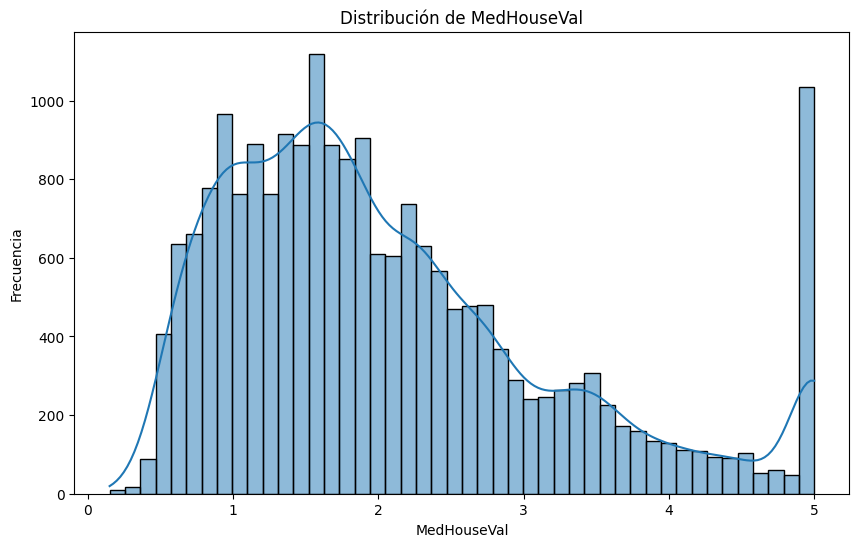

In [4]:
## Visualizar la distribución de la variable objetivo

plt.figure(figsize=(10, 6))
sns.histplot(df['MedHouseVal'], kde=True)
plt.title('Distribución de MedHouseVal')
plt.xlabel('MedHouseVal')
plt.ylabel('Frecuencia')

## 2.-Preparacion de Datos

In [5]:
## Dividir los datos en entrenamiento (80%) y prueba (20%)
x = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("X_train", x_train.shape)
print("X_test", x_test.shape)
print("y_train", y_train.shape)
print("y_test", y_test.shape)

X_train (16512, 8)
X_test (4128, 8)
y_train (16512,)
y_test (4128,)


## 3.- Modelo Base

In [6]:
## Entrenamos el arnol de decision sin restricciones
arbol_base = DecisionTreeRegressor(random_state=42, max_depth=None)
arbol_base.fit(x_train, y_train)
print("Profundidad:", arbol_base.get_depth())
print("Número de hojas:", arbol_base.get_n_leaves())
print("Número de nodos:", arbol_base.tree_.node_count)

Profundidad: 34
Número de hojas: 15854
Número de nodos: 31707


In [7]:
## Evaluamos el modelo con RSME Y R2 tanto como para el conjunto de train como para test
def evaluar_modelo(modelo, x_train, y_train, x_test, y_test):
    y_pred_train = modelo.predict(x_train)
    y_pred_test = modelo.predict(x_test)
    rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
    mae_train = mean_absolute_error(y_train, y_pred_train)
    mae_test = mean_absolute_error(y_test, y_pred=y_pred_test)
    r2_train = r2_score(y_train, y_pred_train)
    r2_test = r2_score(y_test, y_pred_test)
    return rmse_train, rmse_test, mae_train, mae_test, r2_train, r2_test

rmse_train, rmse_test, mae_train, mae_test, r2_train, r2_test = evaluar_modelo(arbol_base, x_train, y_train, x_test, y_test)
print("RMSE train:", round(rmse_train,2))
print("RMSE test:", round(rmse_test,2))
print("MAE train:", round(mae_train,2))
print("MAE test:", round(mae_test,2))
print("R2 train:", round(r2_train,2))
print("R2 test:", round(r2_test,2))


RMSE train: 0.0
RMSE test: 0.7
MAE train: 0.0
MAE test: 0.45
R2 train: 1.0
R2 test: 0.62


Como podemos ver en el R2 de train el modelo acerto en el 100% esto nos habla claramente de un sobre ajuste, ya que en el conjunto de prueba solo acerto un 62%. Entonces posiblemente nuestro modelo no este aprendiendo, sino memorizando lo que aprendio del train

## 4.- Analisis Bias-Variance

In [8]:
## Entrenar multiples modelos variando el parametro de max_dept de 1 a 21
rsmetot = []
rsmetest = []
for i in range(1, 22):
    arbol = DecisionTreeRegressor(max_depth=i, random_state=42)
    arbol.fit(x_train, y_train)
    rmse_train, rmse_test, mae_train, mae_test, r2_train, r2_test = evaluar_modelo(arbol, x_train, y_train, x_test, y_test)
    rsmetot.append(rmse_train)
    rsmetest.append(rmse_test)
    print("Profundidad:", i)
    print("RMSE train:", round(rmse_train,2))
    print("RMSE test:", round(rmse_test,2))
    print("MAE train:", round(mae_train,2))
    print("MAE test:", round(mae_test,2))
    print("R2 train:", round(r2_train,2))
    print("R2 test:", round(r2_test,2))

Profundidad: 1
RMSE train: 0.96
RMSE test: 0.97
MAE train: 0.74
MAE test: 0.75
R2 train: 0.32
R2 test: 0.28
Profundidad: 2
RMSE train: 0.86
RMSE test: 0.87
MAE train: 0.65
MAE test: 0.66
R2 train: 0.45
R2 test: 0.42
Profundidad: 3
RMSE train: 0.79
RMSE test: 0.8
MAE train: 0.59
MAE test: 0.6
R2 train: 0.54
R2 test: 0.51
Profundidad: 4
RMSE train: 0.74
RMSE test: 0.76
MAE train: 0.55
MAE test: 0.56
R2 train: 0.59
R2 test: 0.55
Profundidad: 5
RMSE train: 0.7
RMSE test: 0.72
MAE train: 0.51
MAE test: 0.52
R2 train: 0.64
R2 test: 0.6
Profundidad: 6
RMSE train: 0.66
RMSE test: 0.71
MAE train: 0.47
MAE test: 0.5
R2 train: 0.68
R2 test: 0.62
Profundidad: 7
RMSE train: 0.62
RMSE test: 0.68
MAE train: 0.44
MAE test: 0.47
R2 train: 0.72
R2 test: 0.65
Profundidad: 8
RMSE train: 0.57
RMSE test: 0.65
MAE train: 0.4
MAE test: 0.45
R2 train: 0.76
R2 test: 0.68
Profundidad: 9
RMSE train: 0.52
RMSE test: 0.64
MAE train: 0.36
MAE test: 0.44
R2 train: 0.8
R2 test: 0.68
Profundidad: 10
RMSE train: 0.47
RM

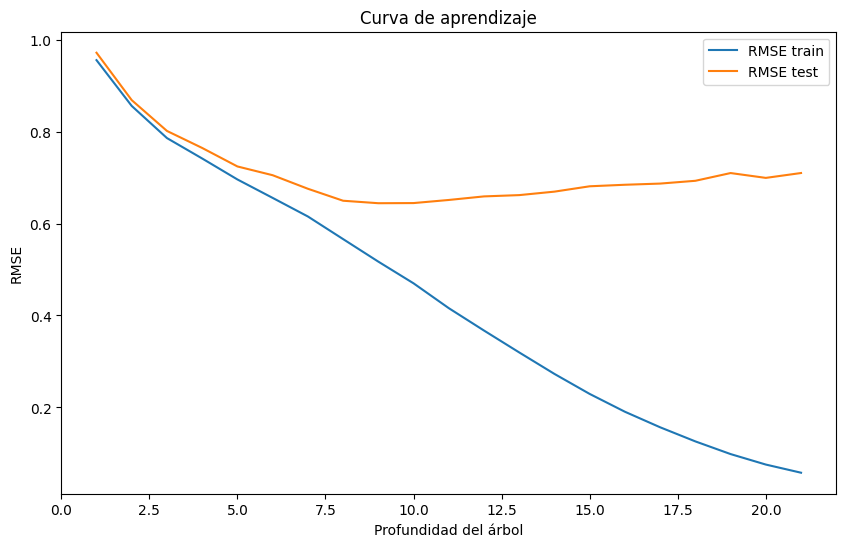

In [9]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, 22), rsmetot, label='RMSE train')
plt.plot(range(1, 22), rsmetest, label='RMSE test')
plt.xlabel('Profundidad del árbol')
plt.ylabel('RMSE')
plt.title('Curva de aprendizaje')
plt.legend()
plt.show()

Segun la grafica en la profundidad entre 8 y 10 fue cuando mejor desempeño tuvo el modelo, siendo cuando ligeramente menor error cometio, aunque ya despues de ahi se medio mantuvo, en esos puntos es ligeramente mas bajo el error y es mayor el r2

## 5.- Poda el arbol

In [26]:
path = DecisionTreeRegressor(random_state=42).cost_complexity_pruning_path(x_train, y_train)
ccp_alphas = path.ccp_alphas
# print("Alphas:", len(ccp_alphas[::500]))
print("Alphas:", len(ccp_alphas))

Alphas: 14833


In [27]:
rmse_train = []
rmse_test = []
## reducimos la toma de alphas, en la practica dice que debe de ser a [::5], pero realmente tomaba demasiado, incluso a 50 tomaba demasiado
## Y me quedan solo 4 hrs para entregar la practica asi que por cuestiones de tiempo
## Lo dejare a 250
ccp_alphas = ccp_alphas[::250]
for ccp_alpha in ccp_alphas:
    arbol = DecisionTreeRegressor(random_state=42, ccp_alpha=ccp_alpha)
    arbol.fit(x_train, y_train)

    y_pred_train = arbol.predict(x_train)
    y_pred_test = arbol.predict(x_test)

    rmse_train.append(np.sqrt(mean_squared_error(y_train, y_pred_train)))
    rmse_test.append(np.sqrt(mean_squared_error(y_test, y_pred_test)))
    print("Alpha:", ccp_alpha)
    print("RMSE train:", round(rmse_train[-1],2))
    print("RMSE test:", round(rmse_test[-1],2))

Alpha: 0.0
RMSE train: 0.0
RMSE test: 0.7
Alpha: 1.2112403102468242e-10
RMSE train: 0.0
RMSE test: 0.7
Alpha: 4.844961240483017e-10
RMSE train: 0.0
RMSE test: 0.7
Alpha: 1.090116279087667e-09
RMSE train: 0.0
RMSE test: 0.7
Alpha: 2.0187338504113736e-09
RMSE train: 0.0
RMSE test: 0.7
Alpha: 3.6640019379452967e-09
RMSE train: 0.0
RMSE test: 0.7
Alpha: 5.117490310080116e-09
RMSE train: 0.0
RMSE test: 0.7
Alpha: 7.751937984423192e-09
RMSE train: 0.0
RMSE test: 0.7
Alpha: 9.811046512246216e-09
RMSE train: 0.0
RMSE test: 0.7
Alpha: 1.3353924418669275e-08
RMSE train: 0.0
RMSE test: 0.7
Alpha: 1.7441860465510253e-08
RMSE train: 0.0
RMSE test: 0.7
Alpha: 2.268249354002035e-08
RMSE train: 0.0
RMSE test: 0.7
Alpha: 2.9100048449618814e-08
RMSE train: 0.0
RMSE test: 0.7
Alpha: 3.709423449613171e-08
RMSE train: 0.01
RMSE test: 0.7
Alpha: 4.605741279068743e-08
RMSE train: 0.01
RMSE test: 0.7
Alpha: 5.6776889534845535e-08
RMSE train: 0.01
RMSE test: 0.7
Alpha: 6.953528746781826e-08
RMSE train: 0.01
RM

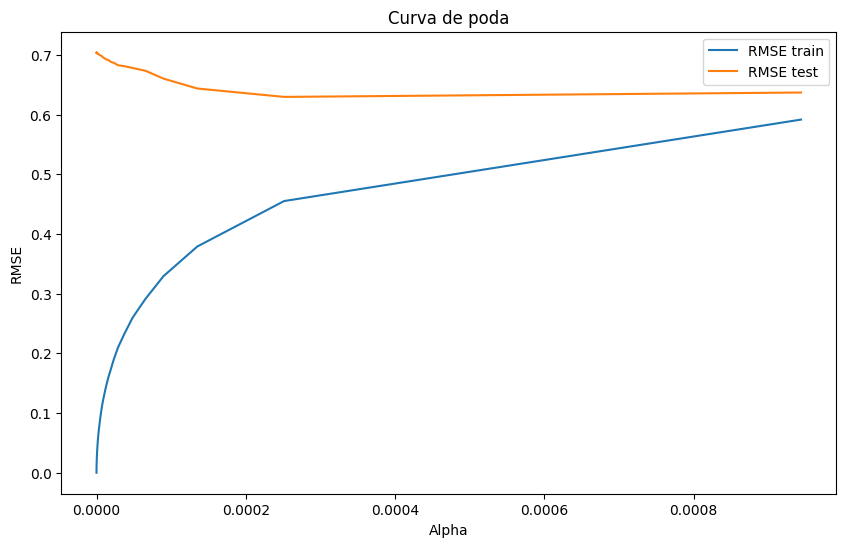

In [28]:
plt.figure(figsize=(10, 6))
plt.plot(ccp_alphas, rmse_train, label='RMSE train')
plt.plot(ccp_alphas, rmse_test, label='RMSE test')
plt.xlabel('Alpha')
plt.ylabel('RMSE')
plt.title('Curva de poda')
plt.legend()
plt.show()

Al ver que hay una poda de arboles, hay un momento donde hace mas eficiente el modelo, eliminando el ruido o ramas que no suman nada. Pero tambien hay otro momento donde empieza a afectar negativamente al modelo eliminando ramas que el modelo si necesita, haciendo mas impreciso al mismo y aumentando el rmse, esto lo podemos ver en la grafica entre el punto 0.0000 y 0.0004, donde el error sube drasticamente hasta para cuando intentamos predecir los mismos datos con el que fue entrenado el modelo.

## 6.- Interpretacion de resultados

¿El modelo base presenta sobreajuste? Explique
Si, segun lo que pudimos ver al principio con la metrica de r2=1.0 evaluando la prediccion contra el grupo de entrenamiento y luego cayendo un .62 cuando evaluamos el grupo de test nos dice que, el modelo no aprendia, solo memorizaba, es por esto que nos estaba generando un sobre ajuste al principio

¿Cómo afecta la profundidad del árbol al error?
Este afecto de ambas maneras, cuando pusimos el max_dep en valores bajos o cero, nos estaba dando buenos resultados ni con el msde ni con el r2, al igual cuando lo subimos arriba de 10, la efectividad del modelo comenzo a disminuir. la mejor profundidad que encontramos fue entre 8 y 10 donde segun las metricas el modelo entrego sus mejores resultados

¿Qué efecto tiene la poda en el modelo?
Nos ayuda a eliminar las 'ramas'que no nos estaban sumando nada al modelo, quitando todo aquello que duplicaba o metia ruido, haciendo que el mse disminuya conforme iba subiendo el alpha como pudimos verlo en la grafica

¿Cuál configuración produce el mejor desempeño?
Para max_dept o profunididad podemos ver en la grafica que su optimo desempeño fue en la profundidad 7-10 donde el rmse alcanzo su valor mas bajo

Y para ccp_alpha por lo visto entre el 0.002 y 0.004 antes de que se empezara a destruir de mas, es mas notorio este cambio en la linea de train, ya que hasta en esa parte, se dispara el rsme para los datos de train, lo que nos da a enteder que el modelo ya no es confiable ni para el train ni para el test

¿Qué variables son más relevantes según el modelo?

Por lo visto la columna de MedInc es la que mas se pudiera relacionar con la columna objetivo (MedHouseVal), ya que el ingreso medinano es lo mas relacionado a la otra columna